In [1]:
import cv2
import numpy as np
import os
import random
import pickle
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

DATA_FOLDER = './data'
IMG_SIZE = 45

In [2]:
# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ
class SequenceGenerator: 
    def __init__(self, data_folder=DATA_FOLDER, out_folder='./test_sequences', test_ratio=0.1):
        self.out_folder = out_folder
        self.char_images = {}
        os.makedirs(out_folder, exist_ok=True)
        for folder in sorted(os.listdir(data_folder)):
            path = os.path.join(data_folder, folder)
            if not os.path.isdir(path):
                continue
            char = folder_to_char(folder)
            files = [f for f in sorted(os.listdir(path))
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]
            split = int(len(files) * (1 - test_ratio))
            imgs = []
            for f in files[split:]:
                img = cv2.imread(os.path.join(path, f), cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    imgs.append(img)
            self.char_images[char] = imgs

    def random_text(self, length=5):
        avail = [c for c, imgs in self.char_images.items() if imgs]
        if not avail:
            raise ValueError("Нет доступных символов для генерации")
        return ' '.join(random.choice(avail) for _ in range(length))

    def char_image(self, char, h=48):
        if char not in self.char_images or not self.char_images[char]:
            return np.zeros((h, h), dtype=np.uint8)
        img = random.choice(self.char_images[char])
        scale = h / img.shape[0]
        return cv2.resize(img, (max(1, int(img.shape[1] * scale)), h))

    def build(self, text, char_h=48, space_w=25):
        parts = [np.full((char_h, space_w), 255, dtype=np.uint8) if c == ' ' else
                 self.char_image(c, char_h) for c in text]
        W = sum(p.shape[1] for p in parts)
        H = max(p.shape[0] for p in parts)
        canvas = np.full((H, W), 255, dtype=np.uint8)
        x = 0
        for p in parts:
            canvas[H - p.shape[0]:, x:x + p.shape[1]] = p
            x += p.shape[1]
        return canvas

    def generate_dataset(self, n=5, length=5):
        dataset = []
        for i in range(n):
            text = self.random_text(length)
            img = self.build(text)
            path = os.path.join(self.out_folder, f'seq_{i:04d}.png')
            cv2.imwrite(path, img)
            dataset.append({'text': text,
                            'text_no_spaces': text.replace(' ', ''),
                            'image_path': path})
        return dataset

In [3]:
# КЛАССИФИКАЦИЯ
class KNNClassifier:
    def __init__(self, data_folder=DATA_FOLDER, train_ratio=0.9):
        (self.X_train, self.Y_train, self.X_test, self.Y_test,
         self.labels, self.label_to_char) = load_dataset(data_folder, train_ratio)
        self.classifiers = {}
        self.best_name = None

    def train(self, k_values=(1, 3, 5, 7)):
        for k in k_values:
            self.classifiers[f'knn{k}'] = KNeighborsClassifier(n_neighbors=k).fit(
                self.X_train, self.Y_train)

    def evaluate(self):
        results = {}
        for name, clf in self.classifiers.items():
            results[name] = accuracy_score(self.Y_test, clf.predict(self.X_test))
            print(f"{name}: accuracy = {results[name]:.4f}")
        self.best_name = max(results, key=results.get)
        print(f"Лучшая модель: {self.best_name} (accuracy={results[self.best_name]:.4f})")
        return results

    def predict(self, img, model=None):
        model = model or self.best_name
        clf = self.classifiers[model]
        feat = center_in_square(img).flatten().reshape(1, -1)
        label = clf.predict(feat)[0]
        dist, _ = clf.kneighbors(feat)
        return self.label_to_char[label], 1.0 / (1.0 + float(np.mean(dist)))

    def save(self, path='knn_models.pkl'):
        with open(path, 'wb') as f:
            pickle.dump({'classifiers': self.classifiers, 'labels': self.labels,
                         'label_to_char': self.label_to_char,
                         'best_name': self.best_name}, f)
        print(f"Модели сохранены: {path}")

    def load(self, path='knn_models.pkl'):
        with open(path, 'rb') as f:
            d = pickle.load(f)
        self.classifiers = d['classifiers']
        self.labels = d['labels']
        self.label_to_char = d['label_to_char']
        self.best_name = d['best_name']
        print(f"Модели загружены: {path}")

In [4]:
# РАСПОЗНАВАНИЕ
class SequenceRecognizer:
    def __init__(self, classifier):
        self.clf = classifier

    def segment(self, image, min_area=50):
        img = image if len(image.shape) == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        img = cv2.bitwise_not(cv2.erode(img, np.ones((3, 3), np.uint8), iterations=1))
        _, thresh = cv2.threshold(img, 127, 255, 0)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        crops = [(x, y, w, h, img[y:y + h, x:x + w])
                 for x, y, w, h in (cv2.boundingRect(c) for c in contours)
                 if w * h > min_area]
        crops.sort(key=lambda c: c[0])
        return crops

    def recognize(self, image, model=None, visualize=False):
        crops = self.segment(image)
        if not crops:
            print("Символы не найдены")
            return "", []
        chars, confs = [], []
        for _, _, _, _, crop in crops:
            ch, conf = self.clf.predict(crop, model)
            chars.append(ch)
            confs.append(conf)
        text = ''.join(chars)
        if visualize:
            self._visualize(image, crops, chars, confs)
        return text, confs

    def _visualize(self, image, crops, chars, confs):
        img_vis = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR) if len(image.shape) == 2 else image.copy()
        for x, y, w, h, _ in crops:
            cv2.rectangle(img_vis, (x, y), (x + w, y + h), (255, 0, 0), 1)
        n = len(crops)
        plt.figure(figsize=(15, 6))
        ax = plt.subplot(2, max(n, 1), (1, n))
        ax.imshow(cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB))
        ax.set_title(f'Сегментация: {n} символов')
        ax.axis('off')
        for i, (_, _, _, _, crop) in enumerate(crops):
            ax = plt.subplot(2, n, n + i + 1)
            ax.imshow((center_in_square(crop) * 255).astype(np.uint8), cmap='gray')
            ax.set_title(f'{chars[i]}\n{confs[i]:.2f}')
            ax.axis('off')
        plt.tight_layout()
        plt.show()

    def recognize_file(self, path, model=None, visualize=True):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Не удалось загрузить: {path}")
        text, confs = self.recognize(img, model, visualize)
        avg = float(np.mean(confs)) if confs else 0
        print(f"Распознанный текст: '{text}'  (символов: {len(text)}, уверенность: {avg:.3f})")
        return text, confs

In [5]:
def folder_to_char(name):
    return {'times': '×', 'X': 'x'}.get(name, name)


def center_in_square(image, target_size=IMG_SIZE):
    h, w = image.shape
    if h > target_size or w > target_size:
        scale = target_size / max(h, w)
        image = cv2.resize(image, (max(1, int(w * scale)), max(1, int(h * scale))))
        h, w = image.shape
    squared = np.zeros((target_size, target_size), dtype=np.uint8)
    y, x = (target_size - h) // 2, (target_size - w) // 2
    squared[y:y + h, x:x + w] = image
    return squared.astype(np.float32) / 255.0


def load_dataset(data_folder=DATA_FOLDER, train_ratio=0.9):
    X_tr, Y_tr, X_te, Y_te, labels, label_to_char = [], [], [], [], [], {}
    for idx, folder in enumerate(sorted(os.listdir(data_folder))):
        path = os.path.join(data_folder, folder)
        if not os.path.isdir(path):
            continue
        char = folder_to_char(folder)
        labels.append(char)
        label_to_char[idx] = char
        files = [f for f in sorted(os.listdir(path))
                 if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]
        split = int(len(files) * train_ratio)
        for i, f in enumerate(files):
            img = cv2.imread(os.path.join(path, f), cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            feat = center_in_square(cv2.bitwise_not(img)).flatten()
            (X_tr if i < split else X_te).append(feat)
            (Y_tr if i < split else Y_te).append(idx)
    return (np.array(X_tr), np.array(Y_tr),
            np.array(X_te), np.array(Y_te), labels, label_to_char)


def generate_sequences(n=5, length=5):
    gen = SequenceGenerator()
    dataset = gen.generate_dataset(n, length)
    fig, axes = plt.subplots(len(dataset), 1, figsize=(16, 4 * len(dataset)))
    for ax, sample in zip(np.atleast_1d(axes), dataset):
        ax.imshow(cv2.imread(sample['image_path'], cv2.IMREAD_GRAYSCALE), cmap='gray')
        ax.set_title(f"Последовательность: {sample['text']}", loc='left', fontweight='bold')
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('test_sequences_examples.png', dpi=120, bbox_inches='tight')
    plt.show()
    print(f"Сгенерировано {len(dataset)} последовательностей")
    return dataset


def train_knn():
    clf = KNNClassifier()
    clf.train(k_values=[1, 3, 5, 7])
    clf.evaluate()
    clf.save('knn_models.pkl')
    return clf


def recognize_sequences(clf, dataset):
    rec = SequenceRecognizer(clf)
    models = list(clf.classifiers.keys())
    stats = {m: {'ok': 0, 'n': 0, 'ch_ok': 0, 'ch_n': 0} for m in models}
    for i, sample in enumerate(dataset):
        img = cv2.imread(sample['image_path'], cv2.IMREAD_GRAYSCALE)
        true = sample['text_no_spaces']
        print(f"\nПоследовательность {i + 1}: '{sample['text']}'")
        for m in models:
            text, _ = rec.recognize(img, m, visualize=False)
            stats[m]['ok'] += text == true
            stats[m]['n'] += 1
            stats[m]['ch_ok'] += sum(1 for a, b in zip(true, text) if a == b)
            stats[m]['ch_n'] += len(true)
            acc = sum(1 for a, b in zip(true, text) if a == b) / len(true) if true else 0
            print(f"  {m}: '{text}' | {acc:>6.1%}")
    print("\nИТОГОВАЯ СТАТИСТИКА")
    for m in sorted(models):
        s = stats[m]
        print(f"{m}: полное совпадение {s['ok']}/{s['n']} ({s['ok'] / max(s['n'], 1):.1%}), "
              f"посимвольно {s['ch_ok']}/{s['ch_n']} ({s['ch_ok'] / max(s['ch_n'], 1):.1%})")
    return stats


def test_custom(clf):
    gen = SequenceGenerator()
    true_text = gen.random_text(6)
    img = gen.build(true_text, char_h=60)
    cv2.imwrite('test_custom.png', img)
    print(f"Истинный текст: '{true_text}'")
    rec = SequenceRecognizer(clf)
    true = true_text.replace(' ', '')
    for m in sorted(clf.classifiers):
        text, _ = rec.recognize_file('test_custom.png', m, visualize=False)
        acc = sum(1 for a, b in zip(true, text) if a == b) / len(true)
        print(f"  {m}: {acc:.1%}")
    print("\nВизуализация (лучшая модель):")
    rec.recognize_file('test_custom.png', clf.best_name, visualize=True)

knn1: accuracy = 0.9955
knn3: accuracy = 0.8783
knn5: accuracy = 0.7615
knn7: accuracy = 0.6971
Лучшая модель: knn1 (accuracy=0.9955)
Модели сохранены: knn_models.pkl


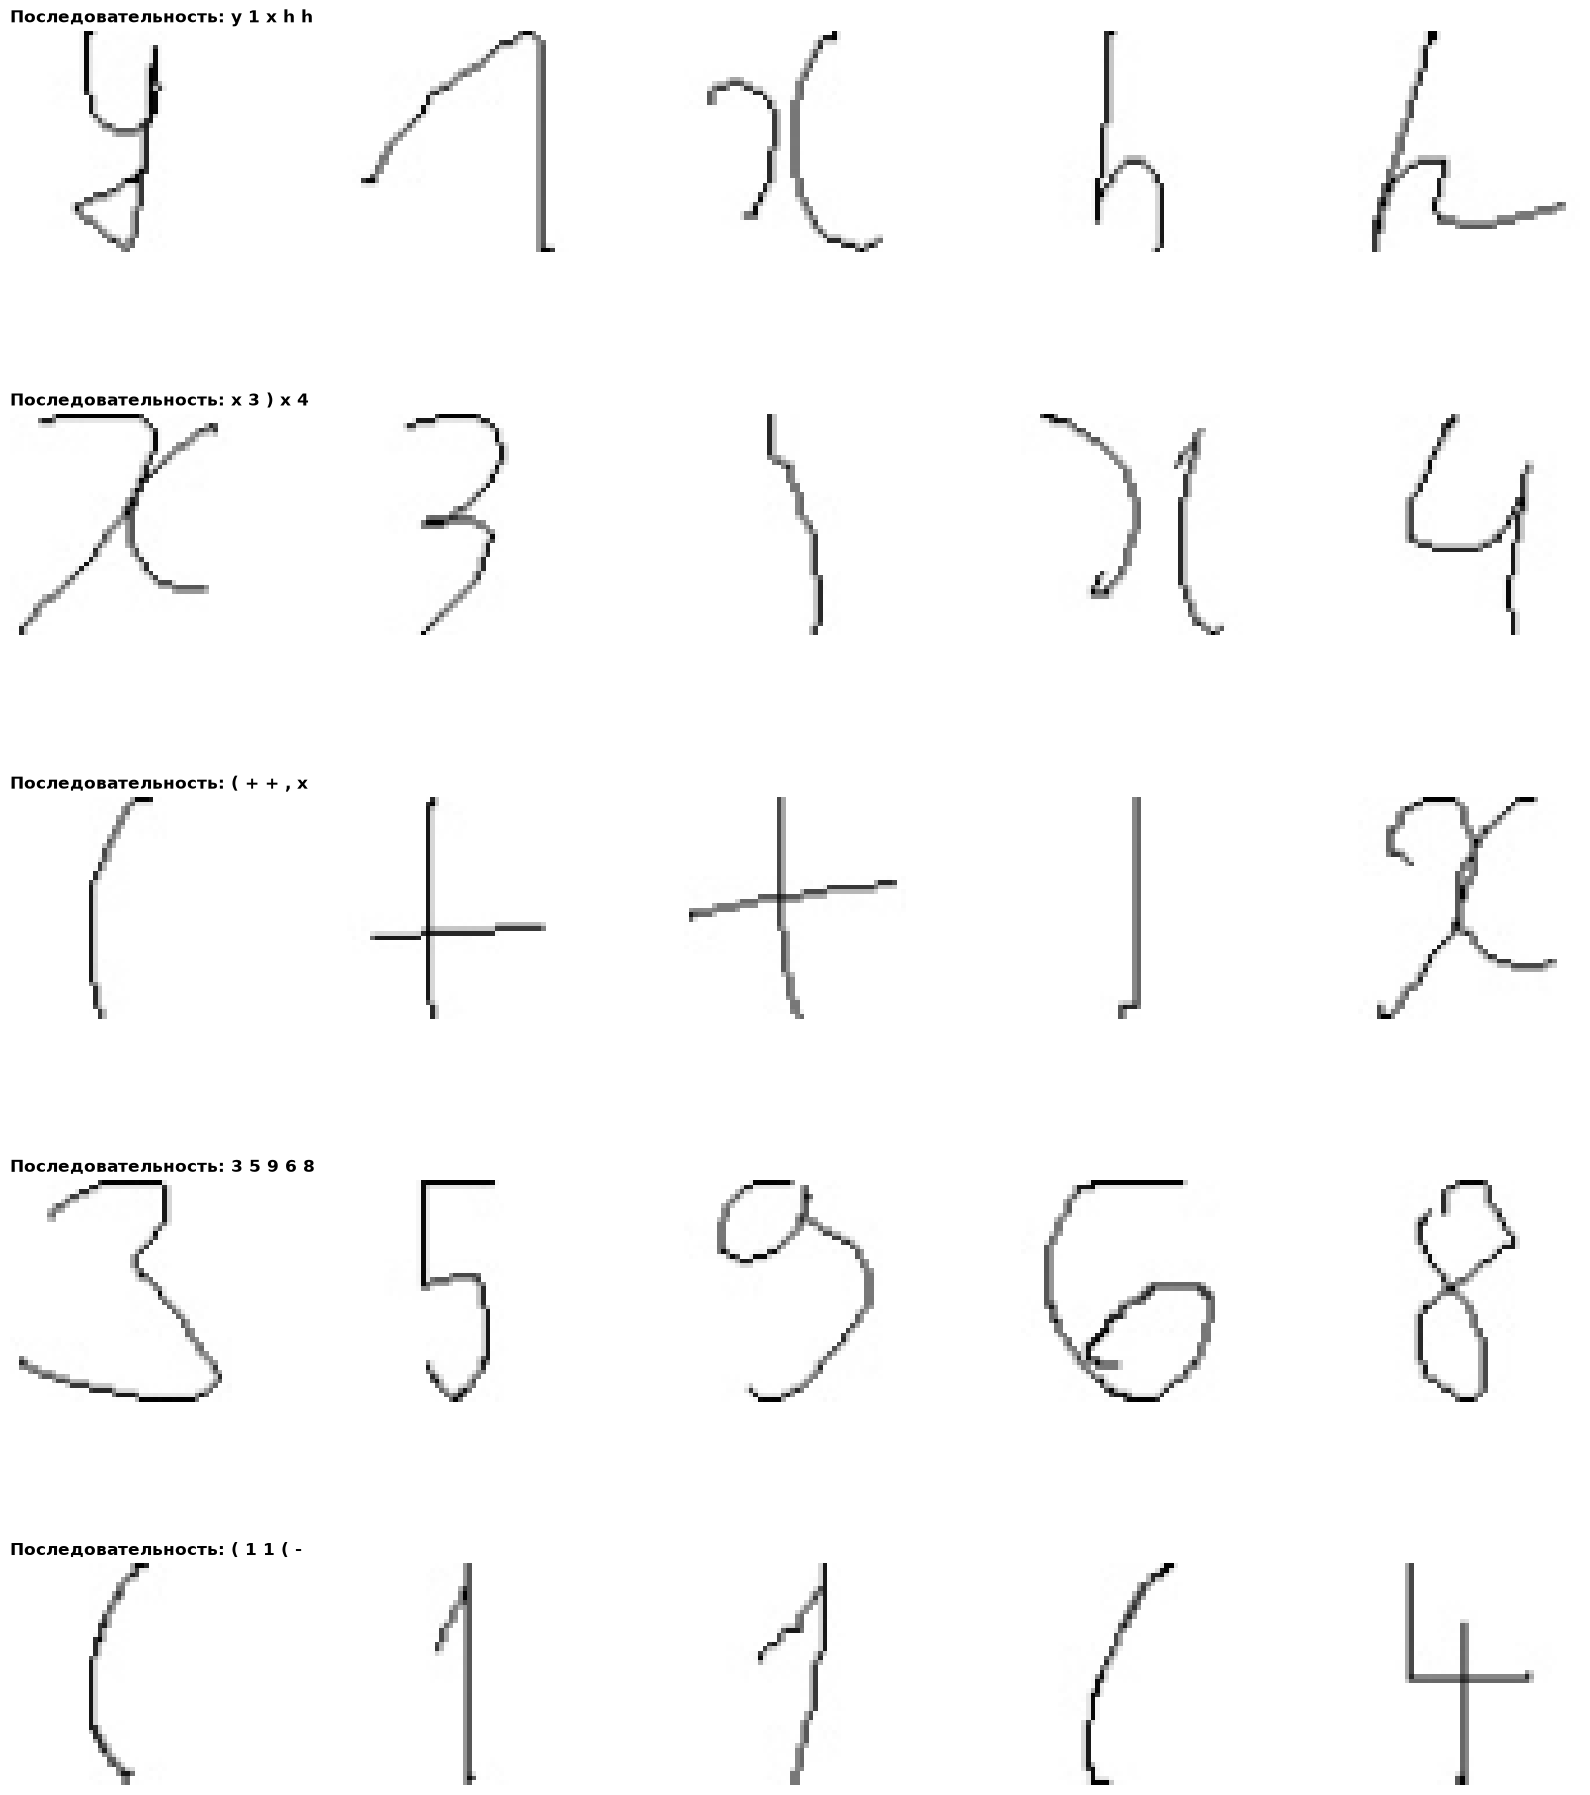

Сгенерировано 5 последовательностей

Последовательность 1: 'y 1 x h h'
  knn1: 'y1)(hh' |  60.0%
  knn3: 'y1)(hh' |  60.0%
  knn5: 'y1)(h(' |  60.0%
  knn7: 'y1)(h(' |  60.0%

Последовательность 2: 'x 3 ) x 4'
  knn1: 'x3)-,(4' |  60.0%
  knn3: 'x3)-,(4' |  60.0%
  knn5: 'x31-,(4' |  40.0%
  knn7: 'x3)-)(4' |  60.0%

Последовательность 3: '( + + , x'
  knn1: '(++,x' | 100.0%
  knn3: '(++,x' | 100.0%
  knn5: '(++1x' |  80.0%
  knn7: '(++1×' |  60.0%

Последовательность 4: '3 5 9 6 8'
  knn1: '-75368' |   0.0%
  knn3: '-75368' |   0.0%
  knn5: '-,5328' |   0.0%
  knn7: '-,5328' |   0.0%

Последовательность 5: '( 1 1 ( -'
  knn1: '(1-1(-' |  40.0%
  knn3: '(1-1(4' |  40.0%
  knn5: '(1-1(4' |  40.0%
  knn7: '(1-1(4' |  40.0%

ИТОГОВАЯ СТАТИСТИКА
knn1: полное совпадение 1/5 (20.0%), посимвольно 13/25 (52.0%)
knn3: полное совпадение 1/5 (20.0%), посимвольно 13/25 (52.0%)
knn5: полное совпадение 0/5 (0.0%), посимвольно 11/25 (44.0%)
knn7: полное совпадение 0/5 (0.0%), посимвольно 11/25 (44.0%

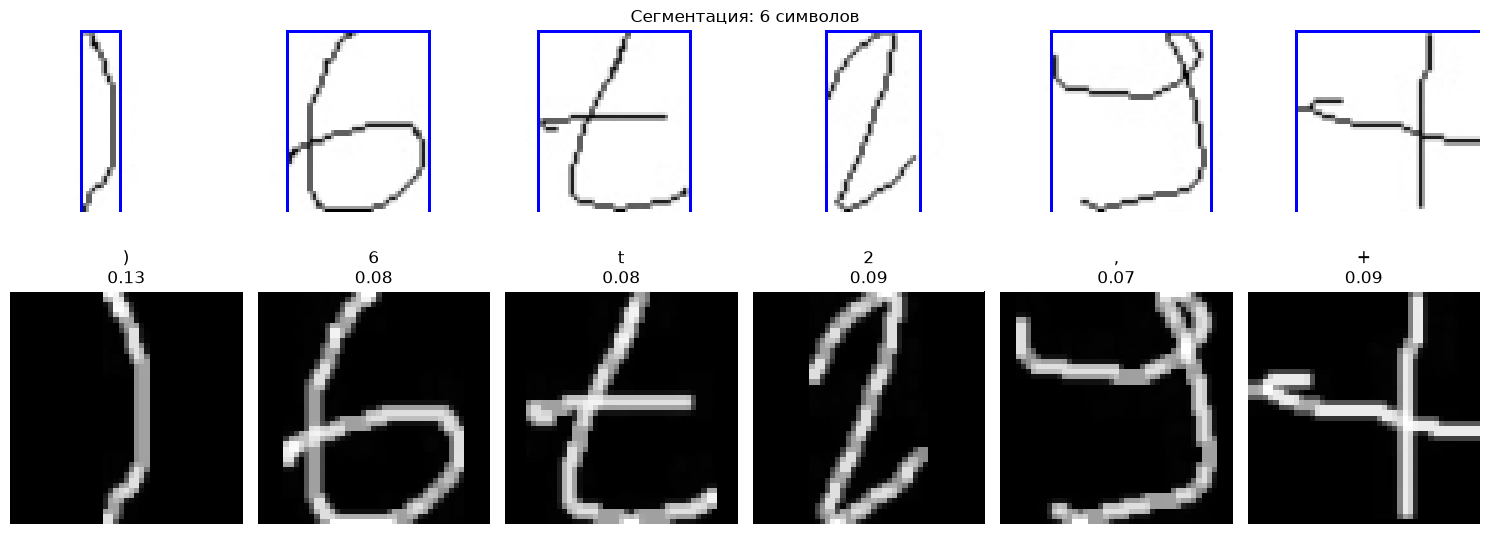

Распознанный текст: ')6t2,+'  (символов: 6, уверенность: 0.091)


In [6]:
if __name__ == '__main__':
    classifier = train_knn()
    dataset = generate_sequences(n=5, length=5)
    recognize_sequences(classifier, dataset)
    test_custom(classifier)